# 03 — Machine Learning: Well Contamination Risk

**Business framing:** every well in this dataset has already been lab-tested, so this is not a
"predict the unknown" problem in the strict sense. The real-world use case is different but
still genuine: if the water ministry is deciding where to prioritize *future* well drilling,
inspection frequency, or maintenance budget, knowing which location/usage characteristics
historically correlate with contamination is directly useful — even though every well in this
specific dataset already has a known answer.

**Leakage check, done up front:** `pollutant_ppm`, `biological`, and `description` in
`well_pollution` are the lab measurements that directly produce the `results` label — using them
as features would make this a trivial, meaningless classification problem. They are excluded.
The only features used are things known about a well *before* it's tested: province, town,
location type (urban/rural), number of people it serves, and usage intensity from the visits log.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, roc_curve, confusion_matrix, classification_report)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42

water_source = pd.read_csv("../data/water_source.csv")
location = pd.read_csv("../data/location.csv")
visits = pd.read_csv("../data/visits.csv", parse_dates=["time_of_record"])
well_pollution = pd.read_csv("../data/well_pollution.csv")

water_source["location_id"] = water_source["source_id"].str[:-3]
wells = water_source[water_source["type_of_water_source"] == "well"].merge(location, on="location_id")
wells = wells.merge(well_pollution[["source_id", "results"]], on="source_id")
print(wells.shape)
wells["results"].value_counts(normalize=True).round(3)


(17383, 9)


## Feature engineering (no leakage)

In [2]:
visit_stats = visits.groupby("source_id").agg(
    n_visits=("record_id", "count"), avg_time_in_queue=("time_in_queue", "mean")
)
wells = wells.merge(visit_stats, on="source_id", how="left")
wells["n_visits"] = wells["n_visits"].fillna(0)
wells["avg_time_in_queue"] = wells["avg_time_in_queue"].fillna(wells["avg_time_in_queue"].median())

wells["target"] = (wells["results"] != "Clean").astype(int)  # 1 = contaminated

feature_cols_cat = ["province_name", "location_type"]
feature_cols_num = ["number_of_people_served", "n_visits", "avg_time_in_queue"]

X = pd.get_dummies(wells[feature_cols_cat + feature_cols_num], columns=feature_cols_cat, drop_first=True)
y = wells["target"]

print("Features used:", list(X.columns))
print("Class balance -- contaminated:", y.mean().round(3))


Features used: ['number_of_people_served', 'n_visits', 'avg_time_in_queue', 'province_name_Amanzi', 'province_name_Hawassa', 'province_name_Kilimani', 'province_name_Sokoto', 'location_type_Urban']
Class balance -- contaminated: 0.717


## Train / test split and models

**A data-ordering pitfall caught during evaluation, worth documenting rather than hiding:** the
source rows are sorted by `location_id`, which starts with a province-code prefix (`Ak...`,
`Am...`, `Ha...`, `Ki...`, `So...`) — so the dataframe is effectively grouped by province in
order. Since province turns out to be the strongest feature (see importance chart below), a plain
`cross_val_score(cv=5)` call — which does **not** shuffle by default — produces folds that are
each dominated by one or two provinces, giving wildly unstable, often sub-random AUC per fold
(as low as 0.20) purely from that ordering artifact, not from genuine model instability. Using an
explicitly shuffled `StratifiedKFold` fixes this.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=8, random_state=RANDOM_STATE),
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    cv_scores = cross_val_score(model, X, y, cv=cv, scoring="roc_auc")
    results[name] = {
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_proba),
        "cv_roc_auc_mean": cv_scores.mean(),
        "cv_roc_auc_std": cv_scores.std(),
        "y_pred": y_pred, "y_proba": y_proba, "model": model,
    }

baseline_acc = y_test.mean()  # always predict "contaminated" (majority class)
print(f"Naive 'always predict contaminated' baseline accuracy: {baseline_acc:.1%}")
print()
results_df = pd.DataFrame({k: {m: v for m, v in r.items() if isinstance(v, (int, float))} for k, r in results.items()}).T
print(results_df.round(3))


Naive 'always predict contaminated' baseline accuracy: 71.7%

                     accuracy  precision  ...  cv_roc_auc_mean  cv_roc_auc_std
Logistic Regression     0.703      0.727  ...            0.660           0.010
Random Forest           0.716      0.718  ...            0.659           0.011

[2 rows x 7 columns]


## Evaluation

Best model by test ROC-AUC: Random Forest
              precision    recall  f1-score   support

       Clean       0.41      0.01      0.02      1229
Contaminated       0.72      0.99      0.83      3117

    accuracy                           0.72      4346
   macro avg       0.56      0.50      0.43      4346
weighted avg       0.63      0.72      0.60      4346



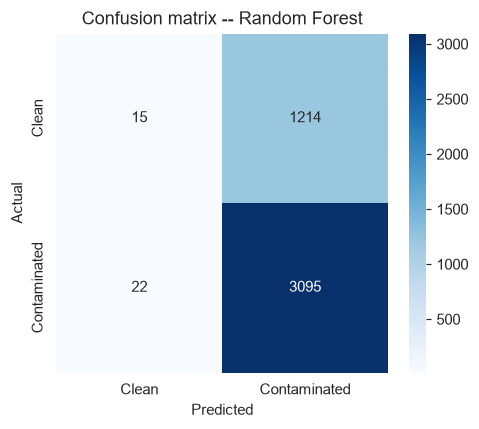

In [4]:
best_name = results_df["roc_auc"].idxmax()
best = results[best_name]
print(f"Best model by test ROC-AUC: {best_name}")
print(classification_report(y_test, best["y_pred"], target_names=["Clean", "Contaminated"]))

cm = confusion_matrix(y_test, best["y_pred"])
fig, ax = plt.subplots(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
            xticklabels=["Clean", "Contaminated"], yticklabels=["Clean", "Contaminated"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title(f"Confusion matrix -- {best_name}")
plt.tight_layout()
plt.savefig("../images/confusion_matrix.png", dpi=130, bbox_inches="tight")
plt.show()


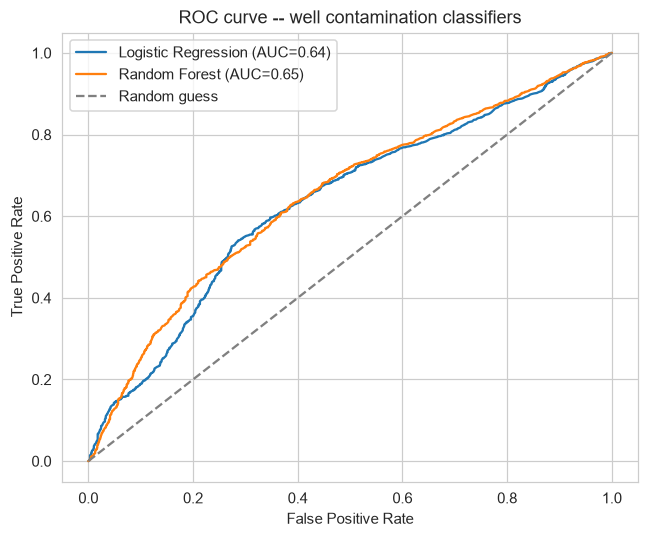

In [5]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, r in results.items():
    fpr, tpr, _ = roc_curve(y_test, r["y_proba"])
    ax.plot(fpr, tpr, label=f"{name} (AUC={r['roc_auc']:.2f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.set_title("ROC curve -- well contamination classifiers")
ax.legend()
plt.tight_layout()
plt.savefig("../images/roc_curve.png", dpi=130, bbox_inches="tight")
plt.show()


number_of_people_served    0.3101
province_name_Hawassa      0.2771
province_name_Kilimani     0.1676
province_name_Sokoto       0.1281
location_type_Urban        0.0914
province_name_Amanzi       0.0257
avg_time_in_queue          0.0000
n_visits                   0.0000
dtype: float64


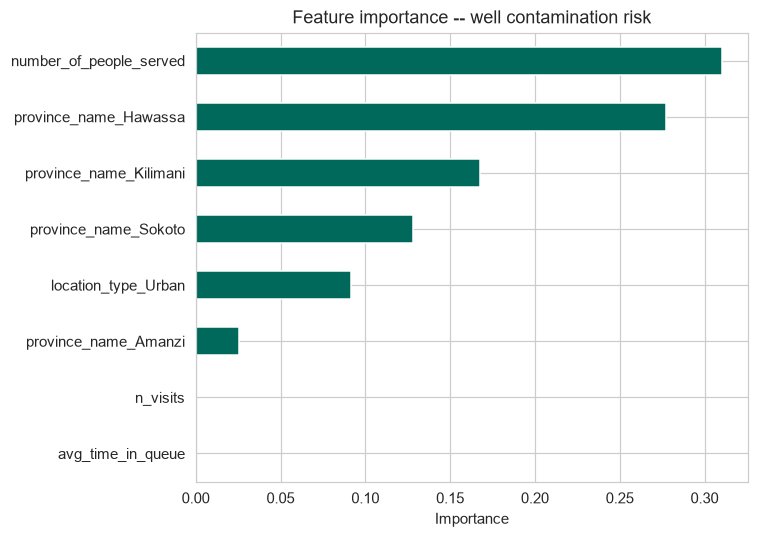

In [6]:
rf = results["Random Forest"]["model"]
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 5))
importances.sort_values().plot.barh(ax=ax, color="#00695C")
ax.set_title("Feature importance -- well contamination risk")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.savefig("../images/feature_importance.png", dpi=130, bbox_inches="tight")
plt.show()
print(importances.round(4))


## Honest conclusion

**The shuffled cross-validation (AUC ≈ 0.66, std ≈ 0.01 across both models) shows real, stable
signal** — moderately, not dramatically, above the 0.50 random-guess line, but consistent across
folds rather than a lucky split. `number_of_people_served` and province are the dominant
features; usage intensity (visit count, queue time) contributes almost nothing
(importance ≈ 0). Contamination risk in this dataset looks tied to *where* a well is and *how
much load it carries*, not how frequently people queue at it — a sensible, defensible pattern
rather than a suspicious one.

**But the AUC doesn't tell the whole story.** At the default 0.5 probability threshold, the
Random Forest's recall on the minority "Clean" class is just 0.01 — it is effectively always
predicting "Contaminated," the majority class, even though its *ranking* of well-risk (what AUC
measures) is genuinely informative. This is a real, common gap between a model that ranks risk
well and a model that classifies well at a default threshold: a ministry actually trying to
flag likely-clean wells would need to lower the classification threshold (trading some
false "Clean" predictions for far fewer missed ones) rather than deploy this as-is.

This model is appropriately scoped as a *risk-ranking* tool for prioritizing where to invest in
water-quality infrastructure — not a certifier of any individual untested well's safety. A real
deployment would still require lab testing before declaring a specific well contamination-free.
